In [12]:
# Graphing a range of motion from lowest to highest distance no remapping needed and windowing option inculded
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

df = pd.read_excel('CALIZaxis0_20Distance.xlsx')
df = df[["distance_mm", "Bx_uT", "By_uT", 'Bz_uT']]

group = df.groupby('distance_mm').agg(["max", 'mean', "min"])
group


Bx_uT                By_uT                Bz_uT               
              max     mean   min   max     mean   min   max     mean   min
distance_mm                                                               
0           -0.03 -0.10912 -0.19  3.93  3.84927  3.74  4.89  4.81008  4.74
1           -0.05 -0.13559 -0.21  5.12  5.03395  4.87 -1.34 -1.57447 -1.67
2           -0.12 -0.18737 -0.28  5.32  5.22740  5.14 -6.58 -6.68587 -6.76
3           -0.13 -0.21393 -0.30  4.61  4.51900  4.44 -8.30 -8.36204 -8.43
4           -0.15 -0.23009 -0.40  3.66  3.53705  3.44 -8.22 -8.33232 -8.43
5           -0.16 -0.22364 -0.31  2.72  2.65359  2.58 -7.70 -7.77359 -7.86
6           -0.14 -0.21481 -0.30  2.00  1.89685  1.82 -6.98 -7.05091 -7.12
7           -0.12 -0.19924 -0.28  1.42  1.33441  1.24 -6.28 -6.35426 -6.41
8           -0.11 -0.18614 -0.27  1.00  0.93062  0.85 -5.70 -5.76813 -5.84
9           -0.10 -0.17392 -0.26  0.70  0.62036  0.54 -5.19 -5.26148 -5.34
10          -0.08 -0.16536 -0.23  0.46  0.39319  0.33 -4.74 -4.81212 -4.88
11          -0.09 -0.15539 -0.23  0.30  0.23359  0.16 -4.37 -4.43175 -4.51
12          -0.07 -0.14645 -0.21  0.23  0.13059  0.04 -4.05 -4.11017 -4.18
13          -0.07 -0.13978 -0.21  0.13  0.05391 -0.03 -3.76 -3.83114 -3.90
14          -0.06 -0.13459 -0.19  0.08  0.00474 -0.08 -3.54 -3.60965 -3.68
15          -0.05 -0.13117 -0.19  0.04 -0.02615 -0.10 -3.35 -3.41470 -3.48
16          -0.05 -0.12465 -0.19  0.03 -0.04891 -0.13 -3.16 -3.22606 -3.31
17          -0.05 -0.11826 -0.19  0.01 -0.06459 -0.16 -2.98 -3.05113 -3.11
18          -0.05 -0.11641 -0.18  0.00 -0.06890 -0.14 -2.84 -2.90224 -2.97
19          -0.04 -0.11391 -0.18  0.01 -0.06827 -0.13 -2.69 -2.75948 -2.82
20          -0.04 -0.11272 -0.18  0.01 -0.06480 -0.14 -2.57 -2.63339 -2.70

In [4]:
xData_All = np.array([5, 4.8, 4.5, 4.3, 4, 3.8, 3.5, 3.3, 3, 2.8, 2.5, 2.3, 2, 1.8, 1.5, 1.3, 1, 0.8, 0.5, 0.3, 0])
#xData_All = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 11.2, 11.5, 11.7, 12, 
                    #12.2, 12.5, 12.7, 13, 13.2, 13.5, 13.7, 14, 14.2, 14.5, 14.7, 15,
                    #15.2, 15.5, 15.7, 16, 16.2, 16.5, 16.7, 17, 18, 19, 20])
#xData_All = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
yData_Xaxis = group["Bz_uT", "mean"].to_numpy()
yData_XaxisMax = group['Bz_uT', 'max'].to_numpy()
yData_XaxisMin = group['Bz_uT', 'min'].to_numpy()

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

21
21


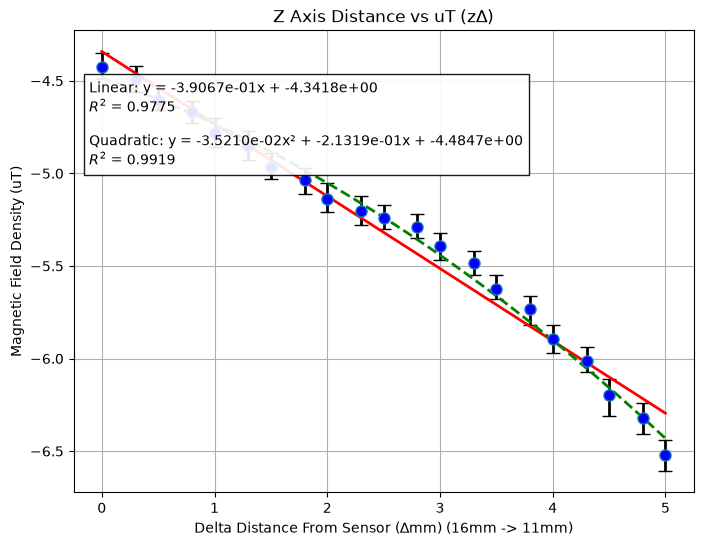

In [5]:
# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)
# ----------------------------------------------

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')



# Display equation on plot
plt.text(0.025, 0.7, lin_eq + "\n\n" + quad_eq,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Delta Distance From Sensor (∆mm) (16mm -> 11mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (z∆)')
plt.grid(True)

# plt.gca().invert_xaxis()
plt.show()

In [6]:
xData_All = np.array([5, 4.8, 4.5, 4.3, 4, 3.8, 3.5, 3.3, 3, 2.8, 2.5, 2.3, 2, 1.8, 1.5, 1.3, 1, 0.8, 0.5, 0.3, 0])
yData_Xaxis = group["By_uT", "mean"].to_numpy()
yData_XaxisMax = group['By_uT', 'max'].to_numpy()
yData_XaxisMin = group['By_uT', 'min'].to_numpy()

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

21
21


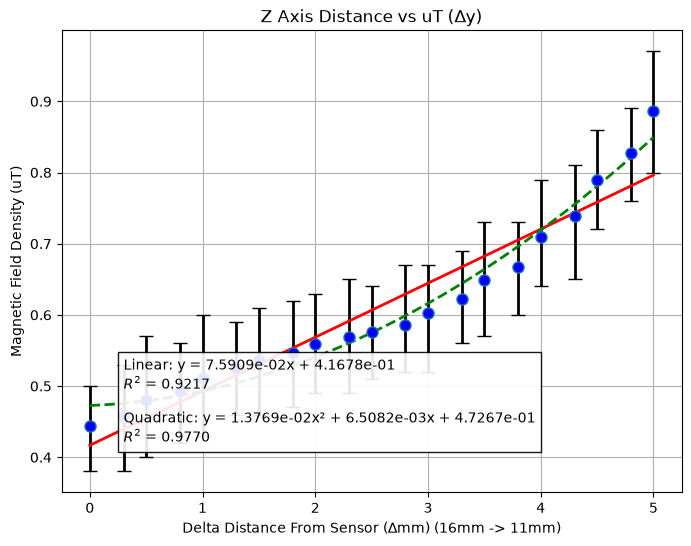

In [7]:
# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)
# ----------------------------------------------

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')

# Display equation on plot
plt.text(0.1, 0.1, lin_eq + "\n\n" + quad_eq,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Delta Distance From Sensor (∆mm) (16mm -> 11mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (∆y)')
plt.grid(True)
# plt.gca().invert_xaxis()
plt.show()

In [8]:
xData_All = np.array([5, 4.8, 4.5, 4.3, 4, 3.8, 3.5, 3.3, 3, 2.8, 2.5, 2.3, 2, 1.8, 1.5, 1.3, 1, 0.8, 0.5, 0.3, 0])
yData_Xaxis = group["Bx_uT", "mean"].to_numpy()
yData_XaxisMax = group['Bx_uT', 'max'].to_numpy()
yData_XaxisMin = group['Bx_uT', 'min'].to_numpy()

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

21
21


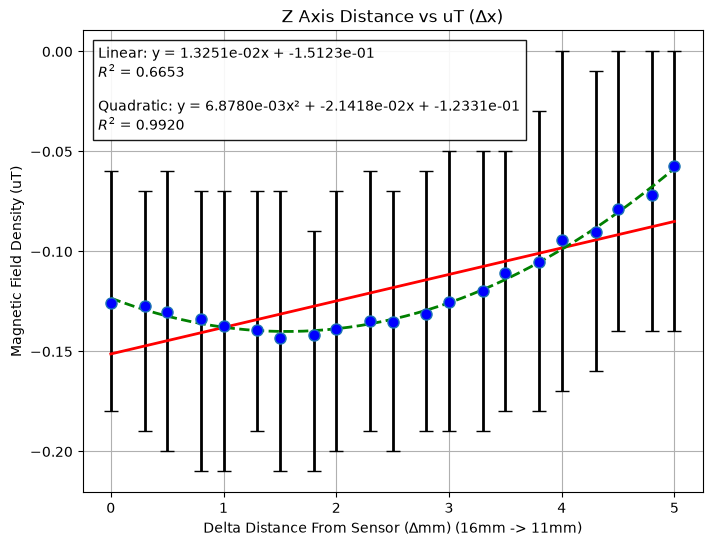

In [9]:
# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)
# ----------------------------------------------

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')

# Display equation on plot
plt.text(0.025, 0.775, lin_eq + "\n\n" + quad_eq,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Delta Distance From Sensor (∆mm) (16mm -> 11mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (∆x)')
plt.grid(True)
# plt.gca().invert_xaxis()
plt.show()

In [10]:
# Window Z Axis

xData_All = np.array([11, 11.2, 11.5, 11.7, 12, 
                    12.2, 12.5, 12.7, 13, 13.2, 13.5, 13.7, 14, 14.2, 14.5, 14.7, 15,
                    15.2, 15.5, 15.7, 16, 16.2, 16.5, 16.7, 17])
yData_Xaxis = group["Bz_uT", "mean"].to_numpy()
yData_XaxisMax = group['Bz_uT', 'max'].to_numpy()
yData_XaxisMin = group['Bz_uT', 'min'].to_numpy()

yData_Xaxis = yData_Xaxis[11:36]
yData_XaxisMax = yData_XaxisMax[11:36]
yData_XaxisMin = yData_XaxisMin[11:36]

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

25
10


In [11]:


# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)

# EXPONENTIAL FIT
exp_coeffs = curve_fit(lambda t,a,b: a*np.exp(b*t), xData_All, yData_Xaxis, p0=(4, 0.1))
A, B = exp_coeffs[0][0], exp_coeffs[0][1]
y_exp_pred = A*np.exp(B*xData_All)

#R^2 Exponential
ss_res_exp = np.sum((yData_Xaxis - y_exp_pred)**2)
r2_exp = 1 - (ss_res_exp / ss_tot)

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c
y_exp_fit = A*np.exp(B*x_fit)

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"
exp_ep = f"Exponential: y = {A:.4e} * $e^{B:.4e}x$\n$R^2$ = {r2_exp:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')
plt.plot(x_fit, y_exp_fit, 'b--', linewidth=2, label=f'Log ($R^2$={r2_exp:.4f})')

# Display equation on plot
plt.text(0.3, 0.025, lin_eq + "\n\n" + quad_eq + "\n\n"+ exp_ep,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Distance From Sensor (mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (z delta) WINDOW')
plt.grid(True)
plt.show()

TypeError: expected x and y to have same length

In [51]:
# Window Y Axis

xData_All = np.array([11, 11.2, 11.5, 11.7, 12, 
                    12.2, 12.5, 12.7, 13, 13.2, 13.5, 13.7, 14, 14.2, 14.5, 14.7, 15,
                    15.2, 15.5, 15.7, 16, 16.2, 16.5, 16.7, 17])
yData_Xaxis = group["By_uT", "mean"].to_numpy()
yData_XaxisMax = group['By_uT', 'max'].to_numpy()
yData_XaxisMin = group['By_uT', 'min'].to_numpy()

yData_Xaxis = yData_Xaxis[11:36]
yData_XaxisMax = yData_XaxisMax[11:36]
yData_XaxisMin = yData_XaxisMin[11:36]

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

25
25


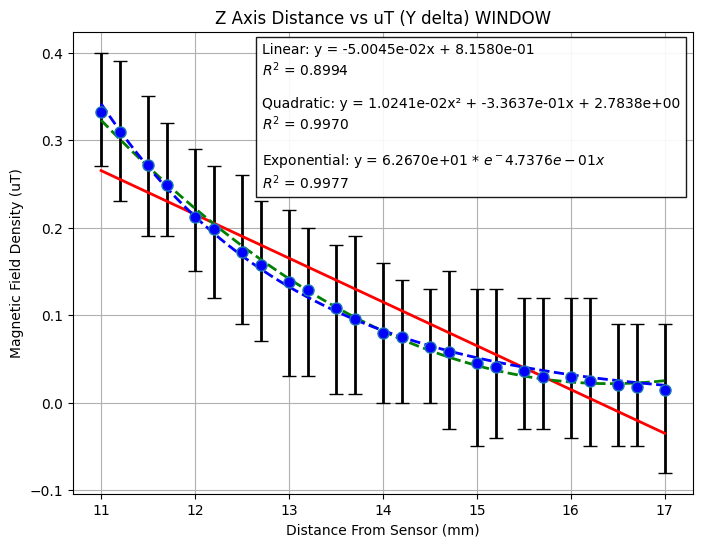

In [52]:
# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)

# EXPONENTIAL FIT
exp_coeffs = curve_fit(lambda t,a,b: a*np.exp(b*t), xData_All, yData_Xaxis, p0=(4, 0.1))
A, B = exp_coeffs[0][0], exp_coeffs[0][1]
y_exp_pred = A*np.exp(B*xData_All)

#R^2 Exponential
ss_res_exp = np.sum((yData_Xaxis - y_exp_pred)**2)
r2_exp = 1 - (ss_res_exp / ss_tot)

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c
y_exp_fit = A*np.exp(B*x_fit)

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"
exp_ep = f"Exponential: y = {A:.4e} * $e^{B:.4e}x$\n$R^2$ = {r2_exp:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')
plt.plot(x_fit, y_exp_fit, 'b--', linewidth=2, label=f'Log ($R^2$={r2_exp:.4f})')

# Display equation on plot
plt.text(0.305, 0.655, lin_eq + "\n\n" + quad_eq + "\n\n"+ exp_ep,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Distance From Sensor (mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (Y delta) WINDOW')
plt.grid(True)
plt.show()

In [53]:
# Window X Axis

xData_All = np.array([11, 11.2, 11.5, 11.7, 12, 
                    12.2, 12.5, 12.7, 13, 13.2, 13.5, 13.7, 14, 14.2, 14.5, 14.7, 15,
                    15.2, 15.5, 15.7, 16, 16.2, 16.5, 16.7, 17])
yData_Xaxis = group["Bx_uT", "mean"].to_numpy()
yData_XaxisMax = group['Bx_uT', 'max'].to_numpy()
yData_XaxisMin = group['Bx_uT', 'min'].to_numpy()

yData_Xaxis = yData_Xaxis[11:36]
yData_XaxisMax = yData_XaxisMax[11:36]
yData_XaxisMin = yData_XaxisMin[11:36]

yerr = [yData_Xaxis - yData_XaxisMin, yData_XaxisMax - yData_Xaxis]
print(len(xData_All))
print(len(yData_Xaxis))

25
25


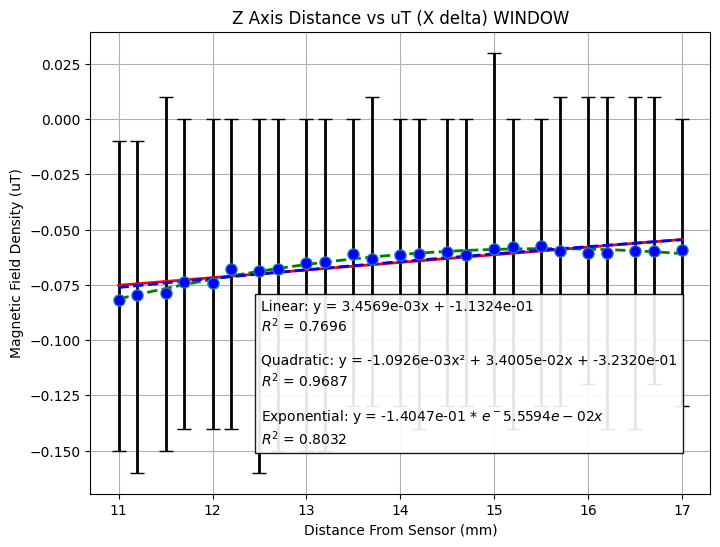

In [54]:

# LINEAR FIT 
lin_coeffs = np.polyfit(xData_All, yData_Xaxis, 1)
lin_slope, lin_intercept = lin_coeffs
y_lin_pred = lin_slope * xData_All + lin_intercept

# R^2 Linear
ss_res_lin = np.sum((yData_Xaxis - y_lin_pred)**2)
ss_tot = np.sum((yData_Xaxis - np.mean(yData_Xaxis))**2)
r2_lin = 1 - (ss_res_lin / ss_tot)

# QUADRATIC FIT
quad_coeffs = np.polyfit(xData_All, yData_Xaxis, 2)
a, b, c = quad_coeffs
y_quad_pred = a*xData_All**2 + b*xData_All + c

# R^2 Quadratic
ss_res_quad = np.sum((yData_Xaxis - y_quad_pred)**2)
r2_quad = 1 - (ss_res_quad / ss_tot)

# EXPONENTIAL FIT
exp_coeffs = curve_fit(lambda t,a,b: a*np.exp(b*t), xData_All, yData_Xaxis, p0=(4, 0.1))
A, B = exp_coeffs[0][0], exp_coeffs[0][1]
y_exp_pred = A*np.exp(B*xData_All)

#R^2 Exponential
ss_res_exp = np.sum((yData_Xaxis - y_exp_pred)**2)
r2_exp = 1 - (ss_res_exp / ss_tot)

# Smooth curve for plotting
x_fit = np.linspace(min(xData_All), max(xData_All), 200)
y_lin_fit = lin_slope * x_fit + lin_intercept
y_quad_fit = a*x_fit**2 + b*x_fit + c
y_exp_fit = A*np.exp(B*x_fit)

# Format equation strings
lin_eq = f"Linear: y = {lin_slope:.4e}x + {lin_intercept:.4e}\n$R^2$ = {r2_lin:.4f}"
quad_eq = f"Quadratic: y = {a:.4e}x² + {b:.4e}x + {c:.4e}\n$R^2$ = {r2_quad:.4f}"
exp_ep = f"Exponential: y = {A:.4e} * $e^{B:.4e}x$\n$R^2$ = {r2_exp:.4f}"

plt.figure(figsize=(8, 6))
plt.errorbar(xData_All, yData_Xaxis, yerr=yerr, fmt='o', capsize=5, ecolor='black', elinewidth=2, markerfacecolor='blue', markersize=8)

plt.plot(x_fit, y_lin_fit, 'r-', linewidth=2, label=f'Linear ($R^2$={r2_lin:.4f})')
plt.plot(x_fit, y_quad_fit, 'g--', linewidth=2, label=f'Quadratic ($R^2$={r2_quad:.4f})')
plt.plot(x_fit, y_exp_fit, 'b--', linewidth=2, label=f'Log ($R^2$={r2_exp:.4f})')

# Display equation on plot
plt.text(0.275, 0.1, lin_eq + "\n\n" + quad_eq + "\n\n"+ exp_ep,
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         bbox=dict(facecolor='white', alpha=0.9))

plt.xlabel('Distance From Sensor (mm)')
plt.ylabel('Magnetic Field Density (uT)')
plt.title('Z Axis Distance vs uT (X delta) WINDOW')
plt.grid(True)
plt.show()